# Week 6 - Bivariate Analysis, part 2

# 1. Lesson: no lesson this week

# 2. Weekly graph question

Suppose you wanted to show the nitrate and phosphate level in a water sample.  What are the advantages and disadvantages of showing this as an area plot, as opposed to two separate line graphs?  How would you adjust the graphs shown to improve the presentation?

In [46]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from IPython.core.pylabtools import figsize
from pandas import read_csv

C:\Users\dmerce1\AppData\Local\Temp\ipykernel_22428\2016790164.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  datearray = pd.date_range(start='2023/01/01', end='2024/01/01', freq='M')


Text(0, 0.5, 'Nitrate level (% of eutrophic value)')

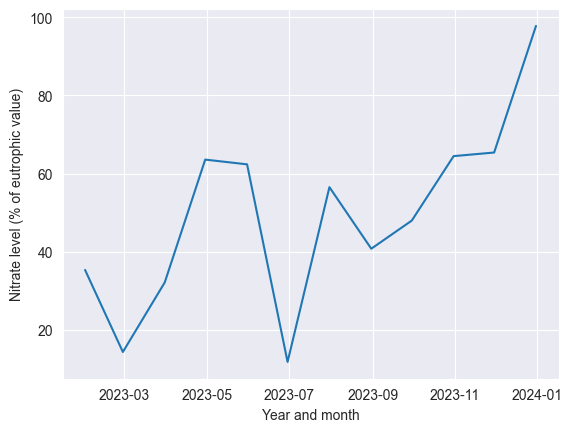

In [47]:
numdates = 12
np.random.seed(0)
time_series = 100 * (np.random.normal(size = numdates) / 5 + np.arange(numdates) / 16)
datearray = pd.date_range(start='2023/01/01', end='2024/01/01', freq='M')
ax = sns.lineplot(x = datearray, y = time_series)
ax.set_xlabel("Year and month")
ax.set_ylabel("Nitrate level (% of eutrophic value)")

C:\Users\dmerce1\AppData\Local\Temp\ipykernel_22428\4159229068.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  datearray = pd.date_range(start='2023/01/01', end='2024/01/01', freq='M')


Text(0, 0.5, 'Phosphate level (% of eutrophic value)')

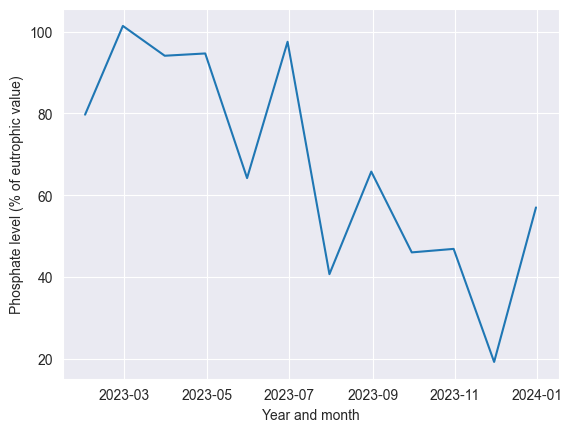

In [48]:
np.random.seed(1)
time_series_2 =  100 * (1 - (np.random.normal(size = numdates) / 8 + np.arange(numdates) / 16))
datearray = pd.date_range(start='2023/01/01', end='2024/01/01', freq='M')
ax = sns.lineplot(x = datearray, y = time_series_2)
ax.set_xlabel("Year and month")
ax.set_ylabel("Phosphate level (% of eutrophic value)")

<Axes: >

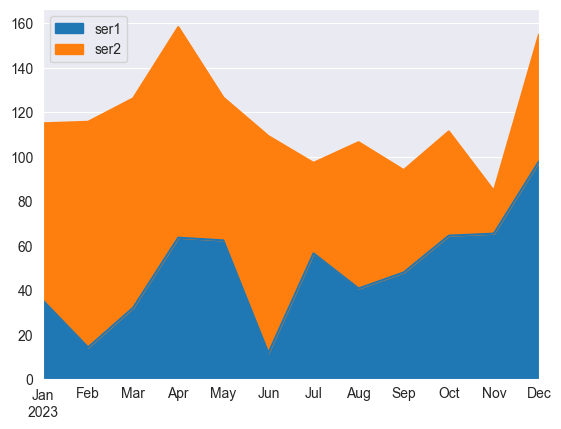

In [49]:
df = pd.DataFrame({'ser1': time_series, 'ser2': time_series_2}, index = datearray)
df.plot.area()

In [50]:
"""The advantage of combining the nitrate and phosphate measurements into a single area plot is that it allows for both items to be viewed in one visualization rather than requiring two separate graphs. This can make is easier to observe overall patterns and see how the nitrate and phosphate levels change to one another over time.

While the stacked area plot has its advantages, the graph can cause for misinterpretation because the individual nutrient values are less clear than in the separate line graphs. The separate line graphs provide a clearer view of each nutrient and make it easier to see the increase and decrease each month.

To improve the visualization, I would place both nitrate and phosphate series on the same line graph using different colors and a legend. The would show a direct comparison between the two nutrients while allowing the ability to see the individual values and trends for each measurement. Additionally, I would include a title and markers to make the monthly values stand out"""

'The advantage of combining the nitrate and phosphate measurements into a single area plot is that it allows for both items to be viewed in one visualization rather than requiring two separate graphs. This can make is easier to observe overall patterns and see how the nitrate and phosphate levels change to one another over time.\n\nWhile the stacked area plot has its advantages, the graph can cause for misinterpretation because the individual nutrient values are less clear than in the separate line graphs. The separate line graphs provide a clearer view of each nutrient and make it easier to see the increase and decrease each month.\n\nTo improve the visualization, I would place both nitrate and phosphate series on the same line graph using different colors and a legend. The would show a direct comparison between the two nutrients while allowing the ability to see the individual values and trends for each measurement. Additionally, I would include a title and markers to make the monthl

# 3. Working on your chosen project datasets this semester

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

### Here are some types of analysis you can do:

- Find correlations between pairs of variables.

- Draw scatterplots, especially when the correlation is large.

- Draw pairplots.

- Draw line graphs and/or area graphs when there is date or time data together with numerical data.

### Conclusions:

- Explain what conclusions you would draw from this analysis: are the data what you expect?  Are the data likely to be usable?  If the data are not useable, find some new data!

- Do you see any outliers?  (Data points that are far from the rest of the data).

- Are any data items highly correlated with each other, suggesting that they are redundant?

- For the line plots, do you see a trend or pattern over time?  Does this suggest that the data are changing over time (drifting) in such a way as to invalidate comparisons?

- Can you think of any confounding variables?  (Third variables that could explain any correlations between other variables.  These third variables may or may not be reported in the dataset.)

Analysis for BRFSS Dataset

In [51]:
#Import Data

df_brfss = pd.read_csv('BRFSS.csv')


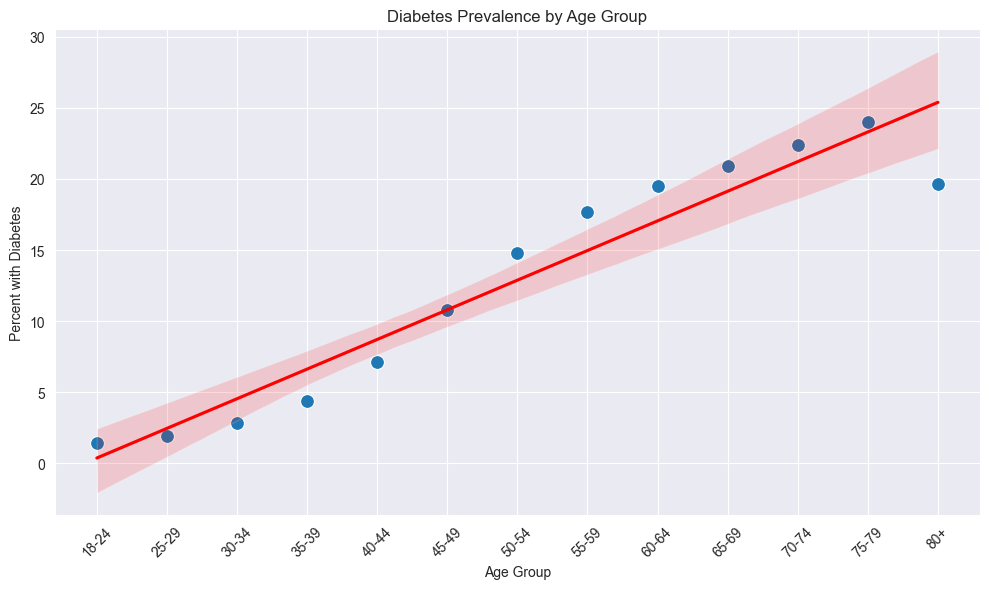

In [52]:
diabetes_age = (df_brfss[df_brfss['_AGEG5YR'] !=14]
                .groupby('_AGEG5YR')['DIABETE4']
                .apply(lambda x: (x ==1).mean()*100))

plt.figure(figsize=(10,6))

sns.scatterplot(
    x=diabetes_age.index,
    y=diabetes_age.values,
    s=100)

sns.regplot(
    x=diabetes_age.index,
    y=diabetes_age.values,
    scatter=False,
    color='red'
)

plt.xticks(
    ticks=range(1,14),
    labels=[
        '18-24','25-29','30-34','35-39','40-44','45-49','50-54','55-59','60-64','65-69','70-74','75-79','80+'], #Age Groups
    rotation=45)

plt.title('Diabetes Prevalence by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Percent with Diabetes')

plt.tight_layout()
plt.show()


In [53]:
"""The scatterplot suggests a strong positive relationship between age and diabetes prevalence. The regression line indicates that diabetes prevalence generally increases as age increases. Respondents in older age groups reported much higher rates of diabetes than younger respondents. This demonstrates that age is an important factor associated with diabetes prevalence. No significant outliers were observed, and the analysis identified a clear trend of increasing diabetes prevalence across age groups. These findings are consistent with expectations, as diabetes is generally more common among older adults. No variables were highly correlated enough to suggest redundancy. Age may help explain why diabetes rates differ across people because diabetes becomes more common as people get older."""

'The scatterplot suggests a strong positive relationship between age and diabetes prevalence. The regression line indicates that diabetes prevalence generally increases as age increases. Respondents in older age groups reported much higher rates of diabetes than younger respondents. This demonstrates that age is an important factor associated with diabetes prevalence. No significant outliers were observed, and the analysis identified a clear trend of increasing diabetes prevalence across age groups. These findings are consistent with expectations, as diabetes is generally more common among older adults. No variables were highly correlated enough to suggest redundancy. Age may help explain why diabetes rates differ across people because diabetes becomes more common as people get older.'

Analysis for NHANES Dataset

In [54]:
#Import Dataset

df_nhanes = pd.read_excel('DEMO_L.xlsx')

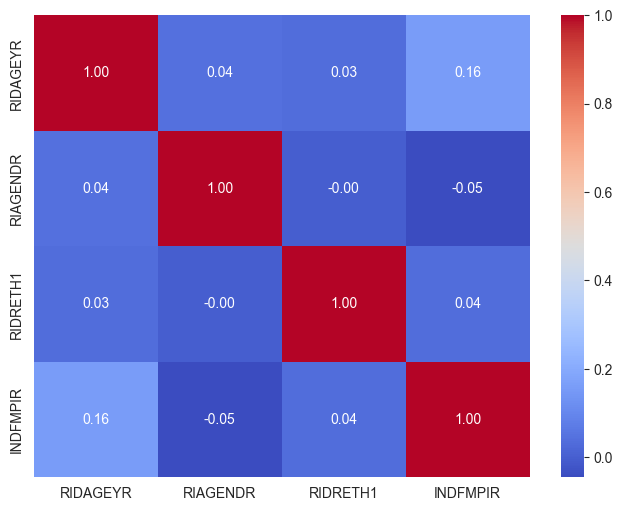

In [55]:
#Correlation Matrix

nhanes_corr = df_nhanes[[
    'RIDAGEYR', #Age
    'RIAGENDR', #Gender
    'RIDRETH1', #Race/Ethnicity
    'INDFMPIR', #Income to Poverty Ratio
]].copy()

corr_martix = nhanes_corr.corr()

plt.figure(figsize=(8,6))

sns.heatmap(corr_martix,annot=True,cmap='coolwarm',fmt='.2f')
plt.show()

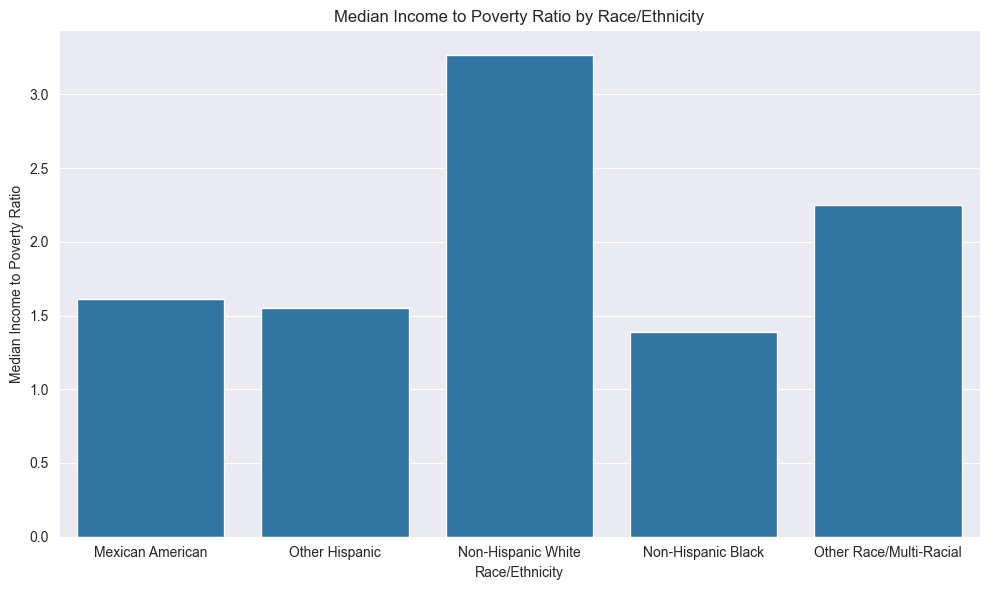

In [56]:
#Line Plot

race_mapping = {
    1: 'Mexican American',
    2: 'Other Hispanic',
    3: 'Non-Hispanic White',
    4: 'Non-Hispanic Black',
    5: 'Other Race/Multi-Racial'
}

race_income = (
    df_nhanes.groupby('RIDRETH1')['INDFMPIR']
    .median()
    .reset_index())
                              
race_income['Race']=race_income['RIDRETH1'].map(race_mapping)

plt.figure(figsize=(10,6))

sns.barplot(
    data=race_income,
    x='Race',
    y='INDFMPIR',
        )

plt.title('Median Income to Poverty Ratio by Race/Ethnicity')
plt.xlabel('Race/Ethnicity')
plt.ylabel('Median Income to Poverty Ratio')

plt.tight_layout()
plt.show()


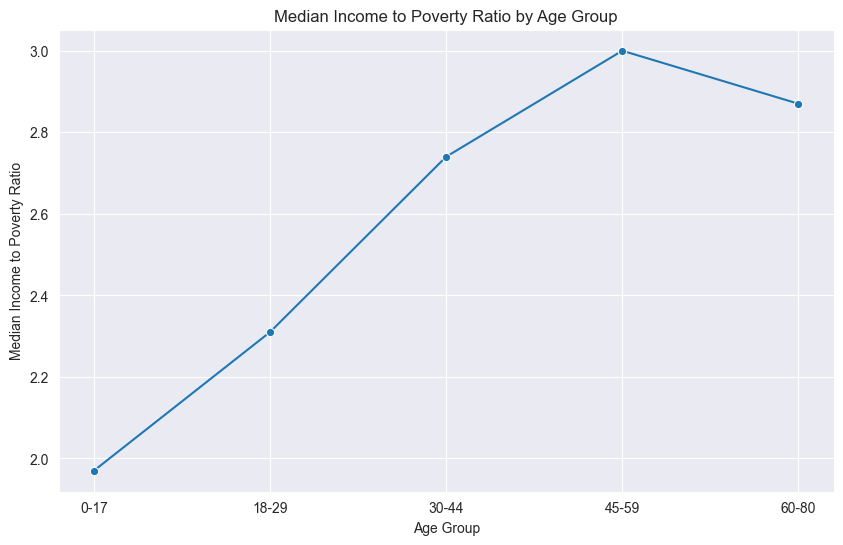

In [57]:
#Median Poverty Ratio by Age Group 

df_plot = df_nhanes.copy()

df_plot['Age_Group'] = pd.cut(df_plot['RIDAGEYR'],
bins=[0,18,30,45,60,80],
labels=['0-17','18-29','30-44','45-59','60-80'])

age_income = (df_plot.groupby('Age_Group', observed=False)['INDFMPIR'].median().reset_index()) 

plt.figure(figsize=(10,6))

sns.lineplot(data=age_income,
             x='Age_Group',
             y='INDFMPIR',
             marker='o')

plt.title('Median Income to Poverty Ratio by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Median Income to Poverty Ratio')

plt.show()

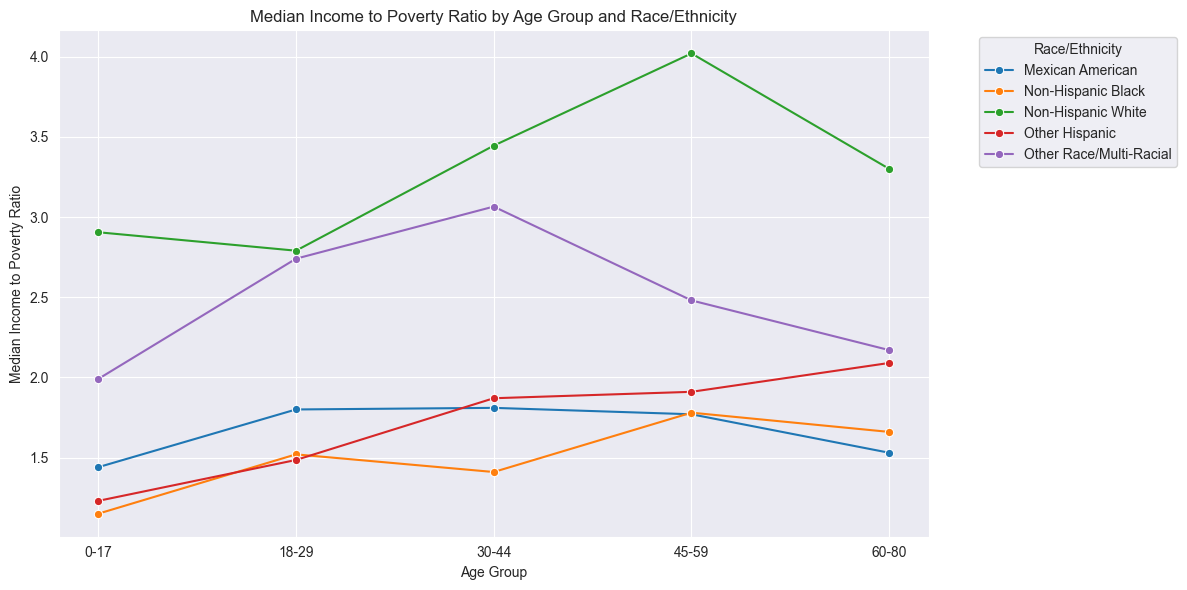

In [58]:
#Median Income to Poverty Ratio by Age and Race/Ethnicity

df_plot = df_nhanes.copy()

df_plot['Race']=df_plot['RIDRETH1'].map(race_mapping)

df_plot['Age_Group'] = pd.cut(df_plot['RIDAGEYR'],
bins=[0,18,30,45,60,80],
labels=['0-17','18-29','30-44','45-59','60-80'])

combined_df = (df_plot.groupby(['Age_Group', 'Race'], observed=False)['INDFMPIR'].median().reset_index()) 

plt.figure(figsize=(12,6))

sns.lineplot(data=combined_df,
             x='Age_Group',
             y='INDFMPIR',
             hue='Race',
             marker='o')

plt.title('Median Income to Poverty Ratio by Age Group and Race/Ethnicity')
plt.xlabel('Age Group')
plt.ylabel('Median Income to Poverty Ratio')

plt.legend(title='Race/Ethnicity', bbox_to_anchor=(1.05,1))
plt.tight_layout()

plt.show()

In [59]:
"""The NHANES analysis suggests a weak relationship among Age, Gender, Race/Ethnicity, and Income to Poverty Ratio. The strongest correlation was seen between Age and Income to Poverty Ratio (r=0.16) suggesting a weak positive relationship. No variables were highly correlated enough for redundancy. This indicates that each variable provides unique demographic or socioeconomic information

The median Income to Poverty Ratio analysis reveals more meaningful patterns than the correlation analysis alone. Median Income to Poverty Ratios generally increased from childhood through middle adulthood before slightly declining with older adults. Difference across racial and ethnic groups were more evident than differences across age groups. Non-Hispanic White respondents consistently reported the highest median income to poverty ratio, while Non-Hispanic Black respondents generally reported lower. Additionally, Mexican American and Other Hispanic respondents tend to have reported lower median ratios than Non-Hispanic White respondents.
  
These findings are consistent with expectations because income will often increase during working years before becoming stable later in life. Additionally, socioeconomic differences are usually seen across ethnic groups. No significant outliers were identified that would meaningfully affect the results of the analysis. The dataset is usable due to the large sample size and demographic representation across age, race/ethnicity, and socioeconomic groups.

The line plots show clear patterns across age groups and race/ethnic groups. Income may act as a confounding variable because socioeconomic status can influence healthcare access, healthcare utilization, and health outcomes. Age may also as a confounding variable because both income and health characteristics usually will vary across age groups.  
"""

'The NHANES analysis suggests a weak relationship among Age, Gender, Race/Ethnicity, and Income to Poverty Ratio. The strongest correlation was seen between Age and Income to Poverty Ratio (r=0.16) suggesting a weak positive relationship. No variables were highly correlated enough for redundancy. This indicates that each variable provides unique demographic or socioeconomic information\n\nThe median Income to Poverty Ratio analysis reveals more meaningful patterns than the correlation analysis alone. Median Income to Poverty Ratios generally increased from childhood through middle adulthood before slightly declining with older adults. Difference across racial and ethnic groups were more evident than differences across age groups. Non-Hispanic White respondents consistently reported the highest median income to poverty ratio, while Non-Hispanic Black respondents generally reported lower. Additionally, Mexican American and Other Hispanic respondents tend to have reported lower median rat

Analysis for CMS Dataset

In [60]:
#Import Data

df_cms = pd.read_excel('CMS_Providers_Cleaned.xlsx')

In [61]:
#Ensure all columns are Numeric

year_cols =['2019','2020','2021','2022','2023']

for col in year_cols: df_cms[col]= pd.to_numeric(df_cms[col], errors='coerce')

#Chronic Disease Specialties
chronic_specialties = ['Cardiology','Pulmonary Disease', 'Neurology', 'Nephrology','Endocrinology','Gastroenterology','Hematology-Oncology','Urology']

#Filter Dataset
chronic_cms = df_cms[df_cms['Specialty'].isin(chronic_specialties)].copy()

chronic_cms

,Specialty,2019,2020,2021,2022,2023,All Physician Specialties
10,Cardiology,24584.0,24277.0,23933.0,23726.0,23752.0,Medical
14,Endocrinology,6613.0,6629.0,6714.0,6803.0,6934.0,Medical
15,Gastroenterology,14876.0,15012.0,15126.0,15278.0,15575.0,Medical
18,Hematology-Oncology,10077.0,10111.0,10128.0,10273.0,10375.0,Medical
27,Nephrology,9632.0,9772.0,9813.0,9959.0,10038.0,Medical
28,Neurology,16413.0,16743.0,17117.0,17505.0,17899.0,Medical
35,Pulmonary Disease,11494.0,11525.0,11580.0,11738.0,11843.0,Medical
54,Urology,9921.0,9925.0,9953.0,9991.0,10158.0,Medical


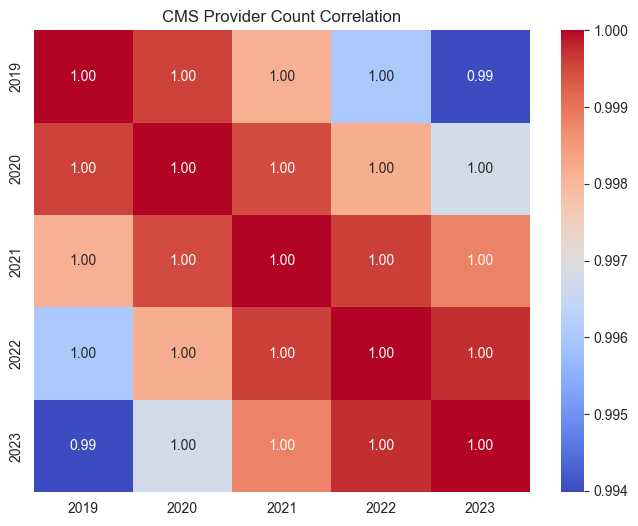

In [62]:
#Correlation Matrix

cms_corr = chronic_cms[['2019','2020','2021','2022','2023']].corr()

plt.figure(figsize=(8,6))

sns.heatmap(cms_corr,annot=True,cmap='coolwarm',fmt='.2f')

plt.title('CMS Provider Count Correlation')
plt.show()

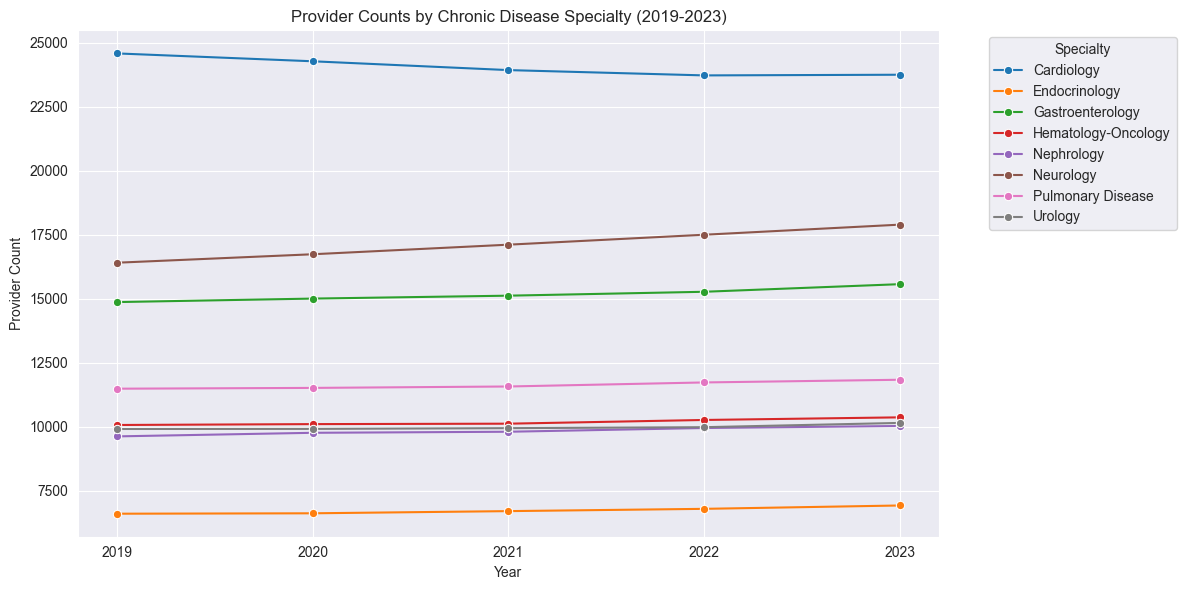

In [63]:
#Provider Counts by Chronic Disease Specialty (2019-2023)

trend_df = chronic_cms.melt(id_vars='Specialty',value_vars=['2019','2020','2021','2022','2023'],var_name='Year',value_name='Provider_Count')

plt.figure(figsize=(12,6))

sns.lineplot(data=trend_df,
             x='Year',
             y='Provider_Count',
             hue='Specialty',
             marker='o')

plt.title('Provider Counts by Chronic Disease Specialty (2019-2023)')
plt.xlabel('Year')
plt.ylabel('Provider Count')

plt.legend(title='Specialty',bbox_to_anchor=(1.05,1))
plt.tight_layout()

plt.show()


In [64]:
"""The CMS analysis identified strong positive correlations between provider counts from 2019 through 2023, with correlation values ranging from .99 to 1.00. These findings indicate that provider availability remained consistent across years and that specialty rankings changed very little over time. Since the yearly variables measure provider counts for the same specialties across multiple years, the high correlations were expected and suggest redundancy among the annual provider count variables.

To focus more on chronic disease management, the original dataset was narrowed down from 52 medical specialties to those that are more directly associated with chronic diseases, including cardiology, pulmonary disease, neurology, nephrology, endocrinology, gastroenterology, hematology-oncology, and urology. This help to focus the analysis on provider availability for specialties most relevant to chronic diseases identified in the BRFSS dataset.

The line graph shows gradual changes in provider availability across chronic disease specialties from 2019 through 2023. Cardiology maintained the largest consistent provider workforce, while endocrinology remained the smallest specialty throughout each year. Neurology and gastroenterology showed small growth over time, while the other specialities stayed stable in their counts. These findings are expected because healthcare provider counts usually change slowly each year.
   
 There were no significant outliers were identified that would affect the results of the analysis. The CMS dataset is very usable due to very little data that is missing, consistent specialty classifications, and the provider counts are reported over multiple years. Factors such as patient demand and the availability of healthcare providers may also influence provider counts over time."""

'The CMS analysis identified strong positive correlations between provider counts from 2019 through 2023, with correlation values ranging from .99 to 1.00. These findings indicate that provider availability remained consistent across years and that specialty rankings changed very little over time. Since the yearly variables measure provider counts for the same specialties across multiple years, the high correlations were expected and suggest redundancy among the annual provider count variables.\n\nTo focus more on chronic disease management, the original dataset was narrowed down from 52 medical specialties to those that are more directly associated with chronic diseases, including cardiology, pulmonary disease, neurology, nephrology, endocrinology, gastroenterology, hematology-oncology, and urology. This help to focus the analysis on provider availability for specialties most relevant to chronic diseases identified in the BRFSS dataset.\n\nThe line graph shows gradual changes in provi

# 4. Storytelling With Data plot

Reproduce any graph of your choice in p. 86-98 of the Storytelling With Data book as best you can.  (The second half of chapter three).  You do not have to get the exact data values right, just the overall look and feel.

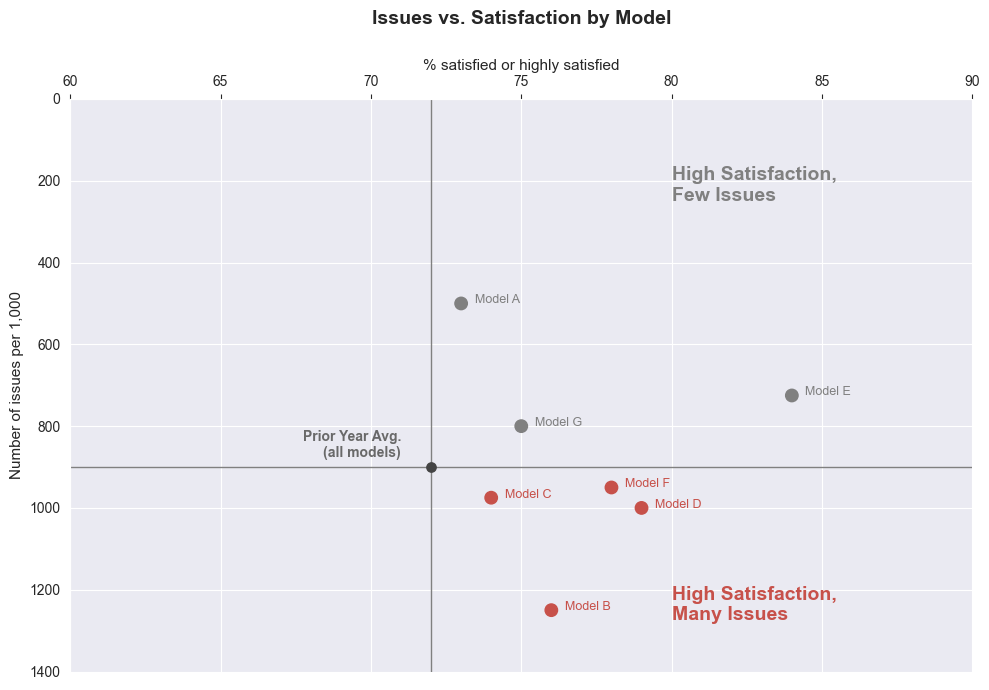

In [65]:
#Data for Scatterplot

#Models shown in the graph
models = ['Model A', 'Model B', 'Model C', 'Model D', 'Model E', 'Model F', 'Model G']

#X Axis Values
satisfaction = [73, 76, 74, 79, 84, 78, 75]

#Y Axis Values
issues = [500, 1250, 975, 1000, 725, 950, 800]

#Color to highlight those models with many issues
colors = ['gray', '#c7514a', '#c7514a', '#c7514a', 'gray', '#c7514a', 'gray']

#Plot Figure
plt.figure(figsize=(10,7))
plt.scatter(satisfaction,issues,c=colors,s=80)

#Labels
for x, y, label, color in zip(satisfaction,issues, models, colors):
    plt.text(x + .45, y, label,fontsize=9,color=color)

#Prior Yr. Average Lines
plt.axvline(x=72, color='gray',linewidth=1)
plt.axhline(y=900, color='gray',linewidth=1)

#Prior Yr. Average Point
plt.scatter(72,900,color='#444444',s=45,zorder=5)
plt.text(71,875,'Prior Year Avg.\n(all models)', ha='right',fontsize=10,weight='bold',color='dimgray')

#Quadrant Labels
plt.text(80,250,'High Satisfaction,\nFew Issues', fontsize=14,weight='bold',color='gray')
plt.text(80,1275,'High Satisfaction,\nMany Issues', fontsize=14,weight='bold',color='#c7514a')

#Axes Labels
plt.xlabel('% satisfied or highly satisfied', fontsize=11)
plt.ylabel('Number of issues per 1,000', fontsize=11)

#Set axis ranges
plt.xlim(60,90)
plt.ylim(1400,0)

#Create tick marks
plt.xticks(range(60,91,5))
plt.yticks(range(0,1401,200))

#Move x axis labels to right on the chart
ax=plt.gca()
ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')

#Remove borders
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title('Issues vs. Satisfaction by Model',fontsize=14,weight='bold',pad=25)

plt.tight_layout()
plt.show()
